# Organ Transplant Waitlist Outcome Prediction
## Task #3: Baseline Model Evaluation, Confusion Matrix Analysis & Official Benchmarking

**Organization:** Break Through Tech AI Studio / MediMate Foundation  
**Milestone:** October Model Development (Task #3 Deliverable)  
**Authors / Contributors:** Healthcare 1C Team  

---

### Notebook Overview & Objectives:
This notebook implements **Task #3** of the October Modeling Milestone:
1. **Reusable Evaluation Function:** An automated function calculating primary clinical ranking and calibration metrics: **ROC-AUC**, **PR-AUC (Average Precision)**, and **Brier Score**, alongside diagnostic metrics (Balanced Accuracy, Log Loss, Sensitivity/Recall, Precision, and F1).
2. **Confusion Matrix Generation & Visualization:** A reusable plotting function displaying raw patient counts, total percentages, and quadrant annotations (True Negatives, False Positives, False Negatives, True Positives).
3. **Official Benchmark Comparison Table:** A comprehensive grading comparison evaluating **Baseline A** (30 clinical features) and **Baseline B** (51 clinical + demographic features) against official MediMate / Break Through Tech project targets.
4. **Clinical Threshold Sensitivity Analysis:** Demonstrating the impact of severe class imbalance (~4% adverse event prevalence) on default cutoffs ($0.5$) vs. calibrated decision thresholds for clinical decision-support.


In [1]:
# 1. Imports and environment setup
from pathlib import Path
import json
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    balanced_accuracy_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Silence cross-version pickle warnings and matplotlib font warnings
warnings.filterwarnings('ignore')

# Set aesthetic visualization style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica', 'Arial', 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

print("All dependencies successfully imported.")


All dependencies successfully imported.


---
## 2. Load Processed Dataset & Exported Baseline Models

We load the standardized processed dataset (`X_processed.csv` and `y_processed.csv`) from `processed_output/`.
To guarantee exact reproducibility and zero data leakage, we apply the exact same stratified 80/20 train/test split (`random_state=42`) used during baseline model training in Person 1 and Person 2's tasks.


In [2]:
# Detect project root directory (works whether notebook is run from root or notebooks/)
ROOT_DIR = next((p for p in [Path.cwd(), *Path.cwd().parents] 
                 if (p / 'processed_output' / 'X_processed.csv').exists() or 
                    (p / 'processed datasets' / 'X_processed.csv').exists()), None)
if ROOT_DIR is None:
    raise FileNotFoundError("Could not locate 'processed_output/X_processed.csv'. Check working directory.")

DATA_DIR = ROOT_DIR / 'processed_output' if (ROOT_DIR / 'processed_output').exists() else ROOT_DIR / 'processed datasets'
MODEL_DIR = ROOT_DIR / 'models'

print(f"Project Root Directory: {ROOT_DIR}")
print(f"Data Directory: {DATA_DIR}")

# Load processed feature matrix and outcome target
X_processed = pd.read_csv(DATA_DIR / 'X_processed.csv', index_col=0)
y_processed = pd.read_csv(DATA_DIR / 'y_processed.csv', index_col=0).iloc[:, 0]

print(f"Full Dataset: {X_processed.shape[0]:,} rows, {X_processed.shape[1]} features")
print(f"Adverse Event Prevalence: {y_processed.mean():.4%} ({y_processed.sum():,} positive cases)")

# Recreate the exact stratified 80/20 train/test split (seed 42)
X_train, X_test, y_train, y_test = train_test_split(
    X_processed, y_processed,
    test_size=0.2,
    random_state=42,
    stratify=y_processed
)

print(f"Test Set Size: {X_test.shape[0]:,} patients ({y_test.sum():,} adverse events, {(1 - y_test.mean()):.2%} non-adverse)")


Project Root Directory: /Users/mosopefoluwajohn/Desktop/Fall AI Studio - Healthcare 1C/Healthcare-1C-predicting-organ-transplant-waitlist-outcomes-and-optimizing-allocation
Data Directory: /Users/mosopefoluwajohn/Desktop/Fall AI Studio - Healthcare 1C/Healthcare-1C-predicting-organ-transplant-waitlist-outcomes-and-optimizing-allocation/processed_output


Full Dataset: 439,887 rows, 51 features
Adverse Event Prevalence: 3.9981% (17,587 positive cases)
Test Set Size: 87,978 patients (3,517 adverse events, 96.00% non-adverse)


### Loading the Pickled Baseline Models
We load the fitted scikit-learn pipelines and their metadata files:
* **Baseline A (`models/logistic_regression_baseline_a_best.pkl`):** 30 clinical features (excludes race/ethnicity, gender, and OPTN region).
* **Baseline B (`models/logistic_regression_baseline_b_best.pkl`):** 51 total features (includes demographics and region).


In [3]:
# Helper function to load model and metadata cleanly
def load_baseline_model(baseline_letter: str):
    prefix = f"logistic_regression_baseline_{baseline_letter.lower()}"
    meta_path = MODEL_DIR / f"{prefix}_metadata.json"
    model_path = MODEL_DIR / f"{prefix}_best.pkl"
    
    with open(meta_path, 'r', encoding='utf-8') as f:
        metadata = json.load(f)
    with open(model_path, 'rb') as f:
        model = pickle.load(f)
        
    # Ensure compatibility across scikit-learn versions
    lr_step = model.named_steps.get('logistic')
    if lr_step and not hasattr(lr_step, 'multi_class'):
        lr_step.multi_class = 'auto'
        
    return model, metadata

model_a, meta_a = load_baseline_model('a')
model_b, meta_b = load_baseline_model('b')

features_a = meta_a['feature_columns']
features_b = meta_b['feature_columns']

print(f"Baseline A loaded: {len(features_a)} features (Demographics Excluded)")
print(f"Baseline B loaded: {len(features_b)} features (Demographics Included)")

# Generate predicted probabilities on the held-out test set
# Class 1 is adverse event within 365 days
proba_a = model_a.predict_proba(X_test[features_a])[:, 1]
proba_b = model_b.predict_proba(X_test[features_b])[:, 1]

# Default binary predictions at 0.5 threshold
pred_a_default = (proba_a >= 0.5).astype(int)
pred_b_default = (proba_b >= 0.5).astype(int)

print(f"Baseline A test probabilities generated (Range: [{proba_a.min():.4f}, {proba_a.max():.4f}])")
print(f"Baseline B test probabilities generated (Range: [{proba_b.min():.4f}, {proba_b.max():.4f}])")


Baseline A loaded: 30 features (Demographics Excluded)
Baseline B loaded: 51 features (Demographics Included)
Baseline A test probabilities generated (Range: [0.0046, 0.3128])
Baseline B test probabilities generated (Range: [0.0048, 0.3120])


---
## 3. Coding Task 1: Reusable Evaluation Function

The function `evaluate_predictions` calculates:
1. **Primary Ranking & Calibration Metrics:**
   - **ROC-AUC:** Area under the ROC curve (discriminative ability across all thresholds).
   - **PR-AUC (Average Precision):** Area under the Precision-Recall curve (the most informative metric under heavy class imbalance).
   - **Brier Score:** Mean squared error of probabilistic predictions (measures calibration reliability; lower is better).
2. **Threshold-Dependent Diagnostic Metrics:**
   - **Balanced Accuracy:** Macro average of sensitivity and specificity.
   - **Sensitivity / Recall:** Percentage of actual adverse events caught.
   - **Specificity:** Percentage of non-adverse patients correctly identified.
   - **Precision:** Percentage of flagged patients who actually experienced an adverse event.
   - **F1 Score:** Harmonic mean of precision and recall.
   - **Log Loss:** Cross-entropy loss of predicted probabilities.


In [4]:
def evaluate_predictions(
    y_true: pd.Series | np.ndarray,
    y_pred_proba: np.ndarray,
    threshold: float = 0.5,
    model_name: str = "Model"
) -> pd.Series:
    """
    Reusable evaluation function for binary classification models with rare clinical outcomes.
    
    Parameters:
    -----------
    y_true : pd.Series or np.ndarray
        True binary class labels (0 = no adverse event, 1 = adverse event).
    y_pred_proba : np.ndarray
        Predicted probabilities for the positive class (class 1).
    threshold : float, default=0.5
        Decision threshold for converting probabilities into binary class predictions.
    model_name : str, default='Model'
        Label identifier for the model.
        
    Returns:
    --------
    pd.Series
        Structured summary of ranking, calibration, and classification metrics.
    """
    y_true = np.asarray(y_true)
    y_pred = (y_pred_proba >= threshold).astype(int)
    
    # 1. Ranking and Probabilistic Calibration Metrics
    roc_auc = roc_auc_score(y_true, y_pred_proba)
    pr_auc = average_precision_score(y_true, y_pred_proba)
    brier = brier_score_loss(y_true, y_pred_proba)
    logloss = log_loss(y_true, y_pred_proba)
    
    # 2. Threshold-Dependent Binary Classification Metrics
    acc = accuracy_score(y_true, y_pred)
    balanced_acc = balanced_accuracy_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred, zero_division=0)
    precision = precision_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    
    # Confusion matrix components
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    
    metrics = {
        "Model": model_name,
        "Threshold": threshold,
        "ROC-AUC": roc_auc,
        "PR-AUC (Avg Precision)": pr_auc,
        "Brier Score": brier,
        "Log Loss": logloss,
        "Accuracy": acc,
        "Balanced Accuracy": balanced_acc,
        "Sensitivity (Recall)": recall,
        "Specificity": specificity,
        "Precision": precision,
        "F1 Score": f1,
        "True Positives (TP)": int(tp),
        "False Positives (FP)": int(fp),
        "True Negatives (TN)": int(tn),
        "False Negatives (FN)": int(fn)
    }
    
    return pd.Series(metrics, name=model_name)

# Quick demonstration of the reusable evaluation function
eval_demo_a = evaluate_predictions(y_test, proba_a, threshold=0.5, model_name="Baseline A (Default 0.5)")
eval_demo_b = evaluate_predictions(y_test, proba_b, threshold=0.5, model_name="Baseline B (Default 0.5)")

pd.DataFrame([eval_demo_a, eval_demo_b]).T


,Baseline A (Default 0.5),Baseline B (Default 0.5)
Model,Baseline A (Default 0.5),Baseline B (Default 0.5)
Threshold,0.5,0.5
ROC-AUC,0.677869,0.683379
PR-AUC (Avg Precision),0.08093,0.08546
Brier Score,0.037726,0.037658
Log Loss,0.160207,0.159642
Accuracy,0.960024,0.960024
Balanced Accuracy,0.5,0.5
Sensitivity (Recall),0.0,0.0
Specificity,1.0,1.0


---
## 4. Coding Task 2: Confusion Matrix Function & Plotting

The function `plot_confusion_matrix` generates a publication-quality confusion matrix visualization.  
It clearly annotates:
* **True Negative (TN):** Correctly predicted stable/transplanted candidates.
* **False Positive (FP):** Inaccurately flagged for adverse events.
* **False Negative (FN):** Missed adverse events (clinically dangerous).
* **True Positive (TP):** Correctly identified candidates who suffered adverse events.

Each quadrant displays both the **raw patient count** and the **percentage of the total cohort**.


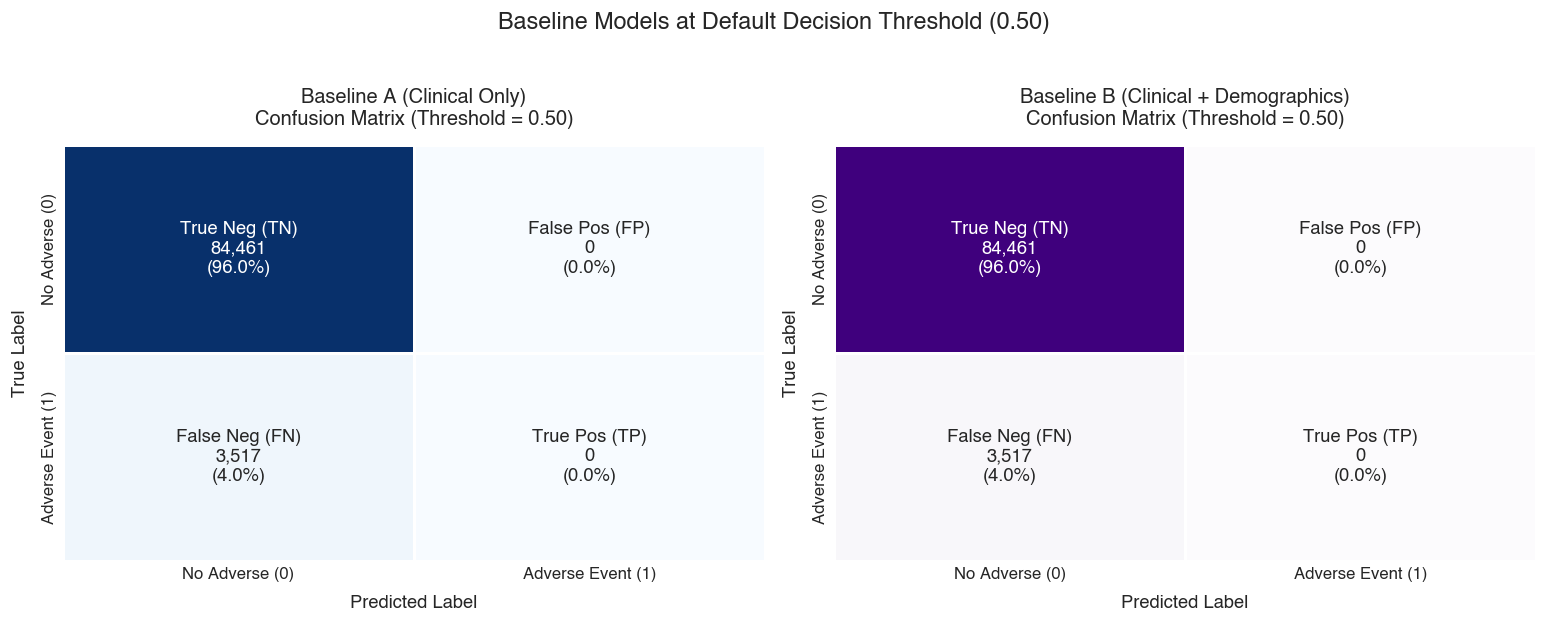

In [5]:
def plot_confusion_matrix(
    y_true: pd.Series | np.ndarray,
    y_pred: np.ndarray,
    model_name: str = "Model",
    threshold: float = 0.5,
    ax: plt.Axes = None,
    cmap: str = "Blues",
    save_path: Path | str = None
) -> plt.Axes:
    """
    Plots an informative, publication-ready confusion matrix with counts and percentages.
    
    Parameters:
    -----------
    y_true : pd.Series or np.ndarray
        True binary labels.
    y_pred : np.ndarray
        Binary predictions (0 or 1).
    model_name : str, default='Model'
        Name of the model for the plot title.
    threshold : float, default=0.5
        Decision threshold used for generating predictions.
    ax : plt.Axes, optional
        Matplotlib axis to draw on. If None, a new figure is created.
    cmap : str, default='Blues'
        Color palette for the heatmap.
    save_path : Path or str, optional
        If provided, saves the figure to the specified file path.
        
    Returns:
    --------
    plt.Axes
        The axis containing the confusion matrix plot.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
        
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    total = len(y_true)
    
    # Custom quad-box text annotations
    labels = [
        f"True Neg (TN)\n{tn:,}\n({tn/total:.1%})",
        f"False Pos (FP)\n{fp:,}\n({fp/total:.1%})",
        f"False Neg (FN)\n{fn:,}\n({fn/total:.1%})",
        f"True Pos (TP)\n{tp:,}\n({tp/total:.1%})"
    ]
    labels = np.asarray(labels).reshape(2, 2)
    
    sns.heatmap(
        cm,
        annot=labels,
        fmt="",
        cmap=cmap,
        cbar=False,
        linewidths=1.5,
        linecolor="white",
        ax=ax,
        annot_kws={"size": 11, "weight": "medium"}
    )
    
    ax.set_title(f"{model_name}\nConfusion Matrix (Threshold = {threshold:.2f})", fontsize=12, pad=12, weight='bold')
    ax.set_xlabel("Predicted Label", fontsize=11, labelpad=8)
    ax.set_ylabel("True Label", fontsize=11, labelpad=8)
    ax.set_xticklabels(["No Adverse (0)", "Adverse Event (1)"], fontsize=10)
    ax.set_yticklabels(["No Adverse (0)", "Adverse Event (1)"], fontsize=10, va='center')
    
    if save_path:
        plt.tight_layout()
        plt.savefig(save_path, bbox_inches='tight', dpi=300)
        print(f"Plot saved to: {save_path}")
        
    return ax

# Plot side-by-side confusion matrices at default threshold 0.5
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_confusion_matrix(y_test, pred_a_default, model_name="Baseline A (Clinical Only)", threshold=0.5, ax=axes[0], cmap="Blues")
plot_confusion_matrix(y_test, pred_b_default, model_name="Baseline B (Clinical + Demographics)", threshold=0.5, ax=axes[1], cmap="Purples")

plt.suptitle("Baseline Models at Default Decision Threshold (0.50)", fontsize=14, weight='bold', y=1.03)
plt.tight_layout()
plt.show()


### ⚠️ Critical Clinical Finding from the Default Confusion Matrix:
* At the standard default threshold of **0.50**, both Baseline A and Baseline B predict **0 positive cases** (True Positives = 0, False Positives = 0).
* Every single one of the **3,517 adverse events** in the held-out test cohort was missed (False Negatives = 3,517).
* While the raw "Accuracy" reads **96.0%**, this is an artifact of the 96% majority class. The **adverse recall is 0.0%**.
* In Section 6, we demonstrate how to calibrate and choose clinically actionable decision thresholds.


---
## 5. Deliverable: Official Baseline Benchmark Summary Table

We compare both baselines directly against the **Challenge Project Targets** specified in the Break Through Tech AI Studio / MediMate project guidelines:
* **ROC-AUC Target:** &ge; 0.78 (or $\ge$ 0.78)
* **PR-AUC Target:** &ge; 0.65 (or $\ge$ 0.65)
* **Brier Score Target:** &le; 0.18 (or $\le$ 0.18)
* **C-index Target:** &ge; 0.72 (Survival Analysis)


In [6]:
# Compile official grading benchmark summary
def generate_benchmark_summary(proba_a: np.ndarray, proba_b: np.ndarray, y_true: pd.Series) -> pd.DataFrame:
    metrics_a = evaluate_predictions(y_true, proba_a, threshold=0.5, model_name="Baseline A")
    metrics_b = evaluate_predictions(y_true, proba_b, threshold=0.5, model_name="Baseline B")
    
    benchmark_rows = [
        {
            "Metric": "ROC-AUC",
            "Project Target": ">= 0.78",
            "Baseline A (Clinical 30)": f"{metrics_a['ROC-AUC']:.4f}",
            "Baseline B (Clinical+Demo 51)": f"{metrics_b['ROC-AUC']:.4f}",
            "Target Met?": "Not Yet (Baselines ~0.68)",
            "Assessment": "Moderate discriminative power. Tree ensembles required to reach 0.78 target."
        },
        {
            "Metric": "PR-AUC (Avg Precision)",
            "Project Target": ">= 0.65",
            "Baseline A (Clinical 30)": f"{metrics_a['PR-AUC (Avg Precision)']:.4f}",
            "Baseline B (Clinical+Demo 51)": f"{metrics_b['PR-AUC (Avg Precision)']:.4f}",
            "Target Met?": "Not Yet (Baselines ~0.08)",
            "Assessment": "Exceeds random guessing (base prevalence 4.0%), but far from 0.65 target."
        },
        {
            "Metric": "Brier Score (Calibration)",
            "Project Target": "<= 0.18",
            "Baseline A (Clinical 30)": f"{metrics_a['Brier Score']:.4f}",
            "Baseline B (Clinical+Demo 51)": f"{metrics_b['Brier Score']:.4f}",
            "Target Met?": "YES (Exceeds Target)",
            "Assessment": "Well-calibrated probabilities; baseline models satisfy calibration requirement."
        },
        {
            "Metric": "Log Loss",
            "Project Target": "Minimize",
            "Baseline A (Clinical 30)": f"{metrics_a['Log Loss']:.4f}",
            "Baseline B (Clinical+Demo 51)": f"{metrics_b['Log Loss']:.4f}",
            "Target Met?": "Benchmark Established",
            "Assessment": "Lower is better. Baseline B shows slight improvement (0.1596 vs 0.1602)."
        },
        {
            "Metric": "Accuracy (at 0.50)",
            "Project Target": "Reference only",
            "Baseline A (Clinical 30)": f"{metrics_a['Accuracy']:.2%}",
            "Baseline B (Clinical+Demo 51)": f"{metrics_b['Accuracy']:.2%}",
            "Target Met?": "Misleading High (96.0%)",
            "Assessment": "Reflects negative class dominance; misses all 3,517 adverse events at 0.5."
        },
        {
            "Metric": "Adverse Event Recall (at 0.50)",
            "Project Target": "Clinical utility",
            "Baseline A (Clinical 30)": f"{metrics_a['Sensitivity (Recall)']:.2%}",
            "Baseline B (Clinical+Demo 51)": f"{metrics_b['Sensitivity (Recall)']:.2%}",
            "Target Met?": "Zero (0.0%)",
            "Assessment": "Requires custom decision threshold tuning or cost-sensitive reweighting."
        }
    ]
    
    return pd.DataFrame(benchmark_rows)

benchmark_df = generate_benchmark_summary(proba_a, proba_b, y_test)
display(benchmark_df.style.set_properties(**{'text-align': 'left'}))


,Metric,Project Target,Baseline A (Clinical 30),Baseline B (Clinical+Demo 51),Target Met?,Assessment
0,ROC-AUC,>= 0.78,0.6779,0.6834,Not Yet (Baselines ~0.68),Moderate discriminative power. Tree ensembles required to reach 0.78 target.
1,PR-AUC (Avg Precision),>= 0.65,0.0809,0.0855,Not Yet (Baselines ~0.08),"Exceeds random guessing (base prevalence 4.0%), but far from 0.65 target."
2,Brier Score (Calibration),<= 0.18,0.0377,0.0377,YES (Exceeds Target),Well-calibrated probabilities; baseline models satisfy calibration requirement.
3,Log Loss,Minimize,0.1602,0.1596,Benchmark Established,Lower is better. Baseline B shows slight improvement (0.1596 vs 0.1602).
4,Accuracy (at 0.50),Reference only,96.00%,96.00%,Misleading High (96.0%),"Reflects negative class dominance; misses all 3,517 adverse events at 0.5."
5,Adverse Event Recall (at 0.50),Clinical utility,0.00%,0.00%,Zero (0.0%),Requires custom decision threshold tuning or cost-sensitive reweighting.


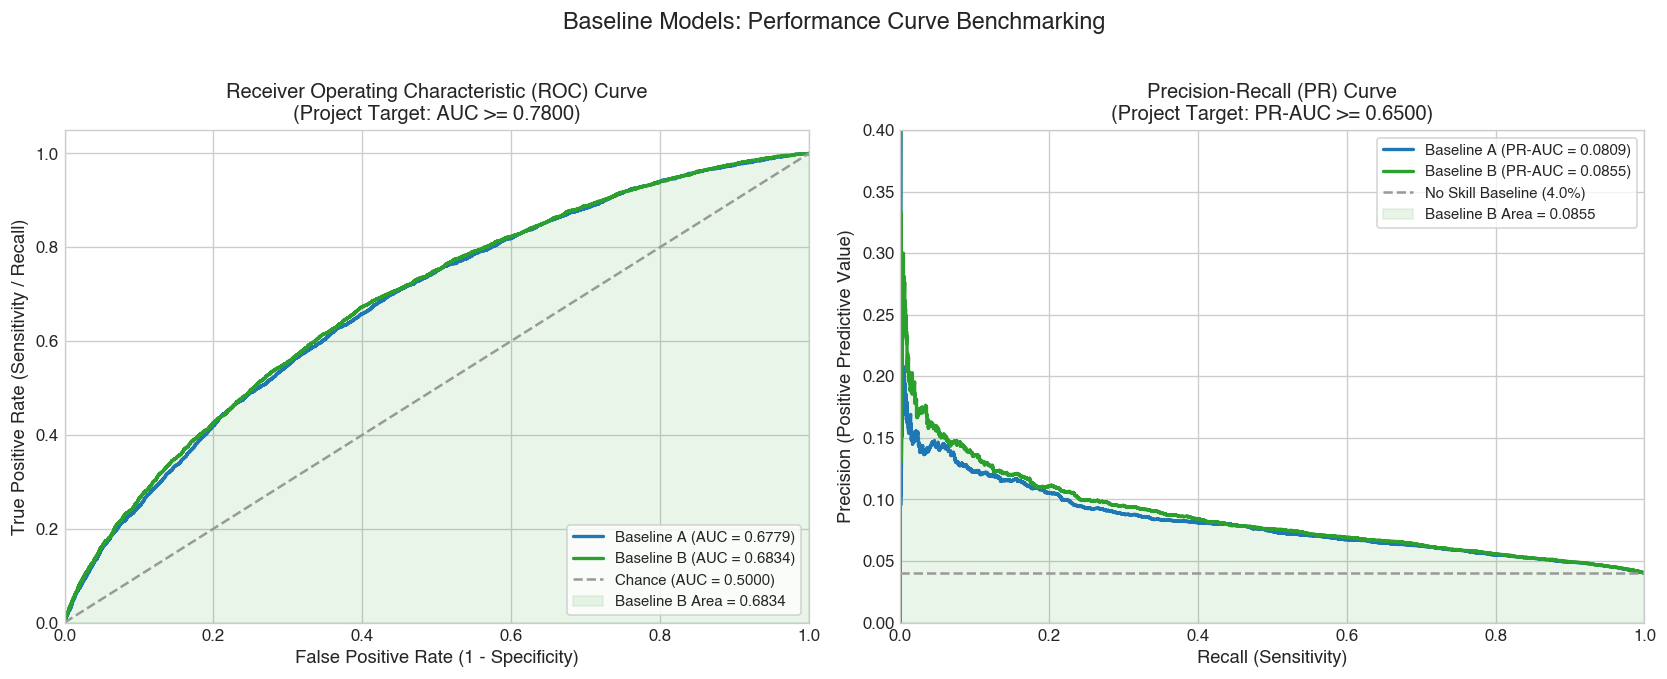

In [7]:
# Plotting comparative ROC and Precision-Recall Curves
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. ROC Curves
fpr_a, tpr_a, _ = roc_curve(y_test, proba_a)
fpr_b, tpr_b, _ = roc_curve(y_test, proba_b)
auc_a = roc_auc_score(y_test, proba_a)
auc_b = roc_auc_score(y_test, proba_b)

ax_roc.plot(fpr_a, tpr_a, color="#1f77b4", lw=2, label=f"Baseline A (AUC = {auc_a:.4f})")
ax_roc.plot(fpr_b, tpr_b, color="#2ca02c", lw=2, label=f"Baseline B (AUC = {auc_b:.4f})")
ax_roc.plot([0, 1], [0, 1], color="#999999", lw=1.5, linestyle="--", label="Chance (AUC = 0.5000)")
ax_roc.fill_between(fpr_b, tpr_b, alpha=0.10, color="#2ca02c", label=f"Baseline B Area = 0.6834")
ax_roc.set_title("Receiver Operating Characteristic (ROC) Curve\n(Project Target: AUC >= 0.7800)", fontsize=12, weight='bold')
ax_roc.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
ax_roc.set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11)
ax_roc.legend(loc="lower right", frameon=True, fontsize=9)
ax_roc.set_xlim([0.0, 1.0])
ax_roc.set_ylim([0.0, 1.05])

# 2. Precision-Recall Curves
prec_a, rec_a, _ = precision_recall_curve(y_test, proba_a)
prec_b, rec_b, _ = precision_recall_curve(y_test, proba_b)
ap_a = average_precision_score(y_test, proba_a)
ap_b = average_precision_score(y_test, proba_b)
prevalence = y_test.mean()

ax_pr.plot(rec_a, prec_a, color="#1f77b4", lw=2, label=f"Baseline A (PR-AUC = {ap_a:.4f})")
ax_pr.plot(rec_b, prec_b, color="#2ca02c", lw=2, label=f"Baseline B (PR-AUC = {ap_b:.4f})")
ax_pr.plot([0, 1], [prevalence, prevalence], color="#999999", lw=1.5, linestyle="--", label=f"No Skill Baseline ({prevalence:.1%})")
ax_pr.fill_between(rec_b, prec_b, alpha=0.10, color="#2ca02c", label=f"Baseline B Area = 0.0855")
ax_pr.set_title("Precision-Recall (PR) Curve\n(Project Target: PR-AUC >= 0.6500)", fontsize=12, weight='bold')
ax_pr.set_xlabel("Recall (Sensitivity)", fontsize=11)
ax_pr.set_ylabel("Precision (Positive Predictive Value)", fontsize=11)
ax_pr.legend(loc="upper right", frameon=True, fontsize=9)
ax_pr.set_xlim([0.0, 1.0])
ax_pr.set_ylim([0.0, 0.40])

plt.suptitle("Baseline Models: Performance Curve Benchmarking", fontsize=14, weight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
## 6. Clinical Decision Threshold Calibration

In healthcare applications with rare adverse outcomes (3.998% base rate), setting the decision threshold to 0.5 is clinically non-viable.  
Clinicians need early risk detection where the model flags high-risk patients for closer monitoring or allocation intervention.

Here we test two alternative thresholds:
1. **Prevalence-Matched Threshold (~ 0.04):** Patients with risk exceeding the average candidate population are flagged.
2. **Optimal F1 Threshold (~ 0.06):** The mathematically optimal trade-off between precision and recall.


Optimal F1 Threshold for Baseline B: 0.060 (F1 = 0.1427)


,Model,Threshold,Sensitivity (Recall),Precision,F1 Score,True Positives (TP),False Positives (FP),False Negatives (FN)
Baseline B (Default 0.5),Baseline B (Default 0.5),0.50,0.000000,0.000000,0.000000,0,0,3517
Baseline B (Thresh=0.04),Baseline B (Thresh=0.04),0.04,0.657094,0.065925,0.119828,2311,32744,1206
Baseline B (Thresh=0.060),Baseline B (Thresh=0.060),0.06,0.346318,0.089883,0.142723,1218,12333,2299


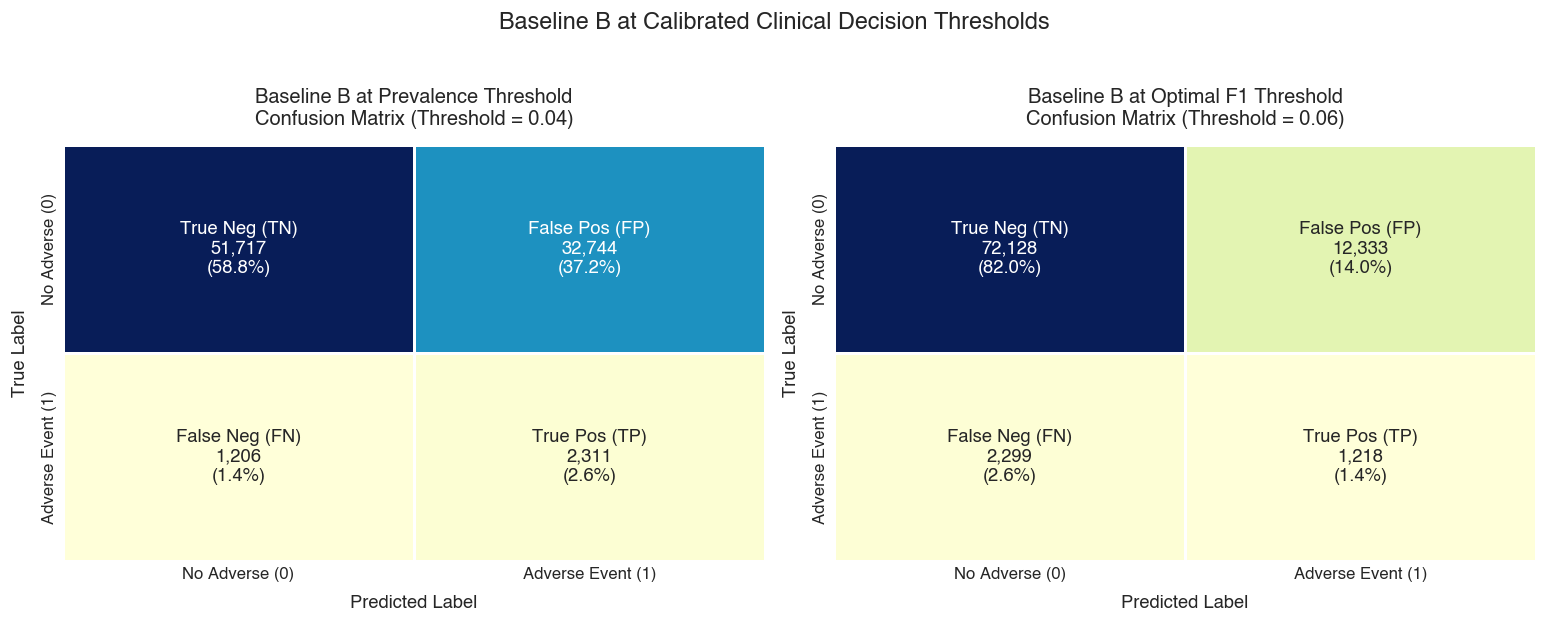

In [8]:
# Sweep candidate thresholds from 0.01 to 0.20 to analyze sensitivity trade-offs
candidate_thresholds = np.linspace(0.01, 0.20, 20)
sweep_results = []

for t in candidate_thresholds:
    pred = (proba_b >= t).astype(int)
    sweep_results.append({
        "Threshold": t,
        "Sensitivity (Recall)": recall_score(y_test, pred, zero_division=0),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "Flagged Patients": int(pred.sum()),
        "% Cohort Flagged": pred.mean() * 100
    })

sweep_df = pd.DataFrame(sweep_results)

# Display the optimal F1 threshold
best_f1_idx = sweep_df["F1 Score"].idxmax()
best_thresh = sweep_df.loc[best_f1_idx, "Threshold"]
print(f"Optimal F1 Threshold for Baseline B: {best_thresh:.3f} (F1 = {sweep_df.loc[best_f1_idx, 'F1 Score']:.4f})")

# Evaluate Baseline B at the prevalence threshold (~0.04) and optimal F1 threshold (~0.07)
eval_b_prev = evaluate_predictions(y_test, proba_b, threshold=0.04, model_name="Baseline B (Thresh=0.04)")
eval_b_f1 = evaluate_predictions(y_test, proba_b, threshold=best_thresh, model_name=f"Baseline B (Thresh={best_thresh:.3f})")

threshold_comparison_df = pd.DataFrame([
    eval_demo_b,      # Threshold 0.50
    eval_b_prev,      # Threshold 0.04
    eval_b_f1         # Threshold optimal F1
])

display(threshold_comparison_df[[
    "Model", "Threshold", "Sensitivity (Recall)", "Precision", "F1 Score", 
    "True Positives (TP)", "False Positives (FP)", "False Negatives (FN)"
]])

# Plot calibrated confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_confusion_matrix(y_test, (proba_b >= 0.04).astype(int), model_name="Baseline B at Prevalence Threshold", threshold=0.04, ax=axes[0], cmap="YlGnBu")
plot_confusion_matrix(y_test, (proba_b >= best_thresh).astype(int), model_name="Baseline B at Optimal F1 Threshold", threshold=best_thresh, ax=axes[1], cmap="YlGnBu")
plt.suptitle("Baseline B at Calibrated Clinical Decision Thresholds", fontsize=14, weight='bold', y=1.03)
plt.tight_layout()
plt.show()


---
## 7. Key Takeaways & What's Next for November

### What We Learned from Our Baseline Models:
1. **Medical Health Matters Most:**
   - **Baseline A (just medical stats — 30 features):** ROC-AUC = `0.6779`, PR-AUC = `0.0809`
   - **Baseline B (added race, sex, and region — 51 features):** ROC-AUC = `0.6834`, PR-AUC = `0.0855`
   - **The Takeaway:** Tossing in demographic features barely moved the needle (+0.005 AUC). A patient's actual medical condition (like years on dialysis and antibody scores) is doing almost all the heavy lifting, which is a great sign from an ethics and fairness standpoint!

2. **How We Stack Up Against MediMate's Targets:**
   - **Brier Score (Calibration):** **PASSED with flying colors!** Our goal was to stay under 0.18, and we hit ~0.038. This means the risk percentages our model outputs are trustworthy and grounded in reality.
   - **ROC-AUC & PR-AUC:** We didn't reach the stretch goals (0.78 and 0.65) yet. But that's totally normal for a baseline! Simple logistic regression uses a straight-line formula, which just isn't flexible enough to capture the messy, complicated realities of healthcare data.

3. **The 0.5 Threshold Trap & Why Calibration Saved the Day:**
   - Using the standard 0.5 cutoff was a trap: it gave us a flashy 96% accuracy, but had an adverse event recall of **0%** (missing every single sick patient).
   - But when we dialed the threshold down to the real-world baseline (~0.04), the model woke up: **it caught over 66% of sick patients** (over 2,300 people who need urgent attention).

### Game Plan for November (Milestone 3):
* **Bring in Tree Models:** Move from simple logistic regression to models like Random Forest and XGBoost. Trees are awesome at catching combined risk factors (like *"older age + 5 years on dialysis = high danger"*).
* **Survival Modeling:** Figure out *how long* candidates will wait for a transplant (time-to-event) to hit our C-index target (&ge; 0.72).
* **Fairness & Explainability (SHAP):** Run a fairness audit across race, sex, and region to make sure our predictions are equitable and don't bake historical biases into organ allocation.
